<a href="https://colab.research.google.com/github/RayaRabbani129/PemMes_2026/blob/main/Minggu11/P02_Week11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Ilustrasi Data Non-Linier

Langkah 1a - Impor Perpustakaan

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting



In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

Langkah 1c - Membuat Data Dummy Non-Linier

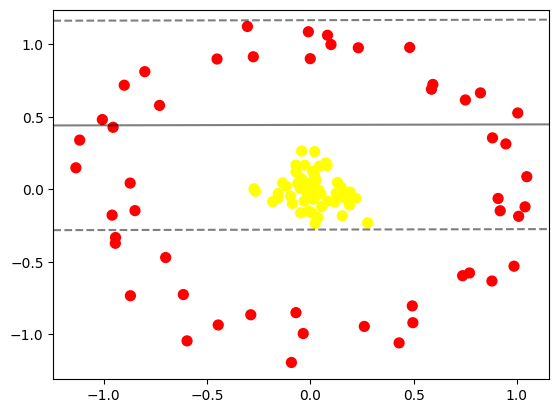

In [3]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[-3.04784473e-01,  1.12232314e+00],
       [ 6.32396460e-03, -1.62424653e-01],
       [-9.59838149e-01, -1.78292970e-01],
       [ 5.93323018e-01,  7.22667363e-01],
       [ 9.46799722e-01,  3.12707137e-01],
       [ 1.25525616e-01, -2.71662241e-02],
       [ 4.93708909e-01, -8.04041159e-01],
       [ 4.29809601e-01, -1.05918810e+00],
       [-9.44314185e-01, -3.72387861e-01],
       [-1.82535547e-01, -8.53284690e-02],
       [ 2.61393790e-01, -9.45583395e-01],
       [-9.43276765e-01, -3.32632629e-01],
       [-2.76124656e-01,  9.13418916e-01],
       [ 2.32385025e-01,  9.75371347e-01],
       [-4.81242479e-02,  7.84417857e-02],
       [-1.57798755e-01, -6.09389816e-02],
       [ 2.77169583e-01, -2.31679122e-01],
       [ 7.67563180e-03, -2.85380380e-02],
       [-4.17723149e-02,  2.63492150e-01],
       [-2.23162456e-02, -1.25532891e-02],
       [ 1.92213926e-01, -1.86518195e-02],
       [-1.11688608e+00,  3.39027169e-01],
       [-9.17140404e-02, -1.19416433e+00],
       [-4.51748908e-01,  8.98027150e-01],
       [ 2.20035186e-01, -6.17404644e-02],
       [-8.74130024e-02, -9.73114474e-02],
       [ 8.29937866e-02, -8.07651569e-02],
       [ 1.81256102e-01, -6.94629308e-02],
       [-1.17865972e-01,  2.16565542e-02],
       [-8.72405073e-01,  4.27378439e-02],
       [ 1.09379408e-02,  1.23676475e-01],
       [ 1.03978258e+00, -1.21037773e-01],
       [ 9.86350504e-01, -5.30337695e-01],
       [-3.02310812e-02, -8.15476414e-02],
       [-6.90890726e-02,  1.19861966e-01],
       [-1.55312090e-01, -2.93833334e-02],
       [ 4.19606880e-02, -8.32752987e-03],
       [-4.87795019e-02,  5.18628366e-03],
       [ 1.89541103e-01, -1.08605197e-01],
       [-9.49163894e-03,  1.08590439e+00],
       [ 2.04913107e-02,  2.59699623e-01],
       [-2.66114154e-02,  1.65945437e-01],
       [ 1.49071941e-01,  1.36580709e-02],
       [-3.44323053e-02, -9.94683059e-01],
       [ 8.12565011e-02,  1.62879371e-01],
       [-8.47712642e-03, -1.51580041e-01],
       [ 1.17648128e-01, -8.80769196e-02],
       [-2.65835322e-01, -1.37971068e-02],
       [ 7.55875134e-02,  1.81606843e-01],
       [ 2.32705336e-02, -2.35436938e-01],
       [-9.69672840e-02, -4.67072314e-02],
       [ 1.04823213e+00,  8.66722188e-02],
       [ 1.92290769e-02,  1.00049678e-01],
       [-6.15034635e-01, -7.25818339e-01],
       [ 3.60428460e-02, -1.93293820e-01],
       [ 8.79424364e-01, -6.32575857e-01],
       [-6.13918888e-02,  3.87558433e-02],
       [-1.14459622e-02,  4.08426604e-02],
       [ 8.23808860e-01,  6.64429143e-01],
       [-8.49148011e-01, -1.47127426e-01],
       [-1.13524540e+00,  1.47863389e-01],
       [ 9.19459146e-01, -1.48060194e-01],
       [-1.34415355e-01,  4.40408338e-02],
       [ 1.31414402e-01,  4.68417482e-02],
       [-9.55155158e-01,  4.27284475e-01],
       [-9.01183818e-01,  7.17155775e-01],
       [ 4.81278666e-01,  9.77540476e-01],
       [ 2.76073306e-02,  6.29275112e-02],
       [-7.00449477e-01, -4.70652793e-01],
       [-4.45933278e-01, -9.35651364e-01],
       [-8.71257739e-01, -7.34051280e-01],
       [-8.01580928e-01,  8.10682755e-01],
       [ 7.50817400e-01,  6.15742828e-01],
       [ 7.37420966e-01, -5.95876377e-01],
       [ 9.09268300e-01, -6.34800421e-02],
       [ 4.38876261e-02,  1.59444670e-01],
       [ 1.00446264e+00,  5.25983520e-01],
       [-2.80888515e-04,  9.00354470e-01],
       [ 7.70760627e-01, -5.77191958e-01],
       [-6.97150612e-02,  1.66870731e-01],
       [-1.00720203e+00,  4.80531036e-01],
       [-7.30122654e-01,  5.78082698e-01],
       [ 1.54728128e-01, -1.83299618e-01],
       [ 5.04312544e-02, -2.77330468e-02],
       [-3.49256670e-02,  5.74411594e-02],
       [ 5.52753200e-02, -1.19547003e-01],
       [ 4.18435744e-04,  2.43102535e-02],
       [ 8.33291760e-02,  1.06168339e+00],
       [ 1.51111250e-01, -5.36494565e-02],
       [ 1.49546242e-02, -6.83387534e-02],
       [ 5.86510657e-01,  6.89728017e-01],
       [ 8.81955244e-01,  3.54414635e-01

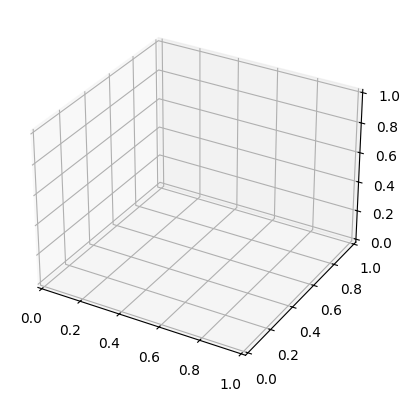

In [4]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180),
         X=fixed(X), y=fixed(y))

#Langkah 2 - Memasang Model


In [5]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

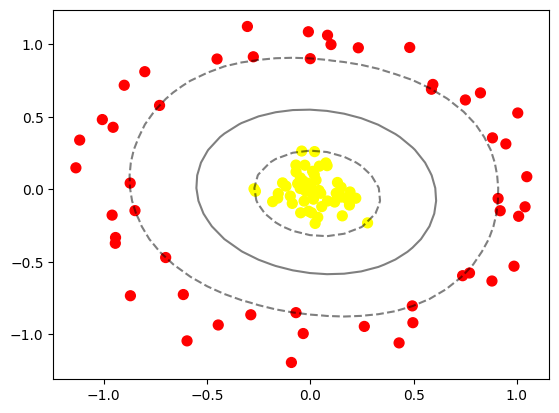

In [6]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')